Disclaimer: AI was used in this notebook to translate some code from R to Python (mainly the imports & how they are used)

Note: I apologise for how long this notebook is. At first I misunderstood the assignment for this part of the coursework, thinking that only the scatter plots were required. I did not want to let them go to waste so I have left them in and used them for some of the classifications. I have also left in some mistakes I made (that were corrected of course) because I think I have learnt a lot from them and will make for more of an interesting presentation. 

In [87]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy.stats as stats
import seaborn as sns
import statsmodels.api as sm

from sklearn import (
discriminant_analysis, naive_bayes, svm, model_selection, metrics,
preprocessing, pipeline, inspection
)
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.inspection import DecisionBoundaryDisplay

plt.rcParams['figure.figsize'] = (12,8)

In [3]:
import sqlite3
conn = sqlite3.connect('econ1205_CW_database.db')
cursor = conn.cursor()
cursor.execute("SELECT name FROM sqlite_master WHERE type='table';")
print(cursor.fetchall())

[('carbon_gdp_intensity',), ('consumer_price_inflation',), ('gdp',), ('gdp_per_capita',), ('gdp_per_capita_growth',), ('net_energy_imports',), ('countries',)]


In [4]:
# Read in the tables
df_carbon = pd.read_sql_query("SELECT * FROM carbon_gdp_intensity", conn)
df_inflation = pd.read_sql_query("SELECT * FROM consumer_price_inflation", conn)
df_gdp = pd.read_sql_query("SELECT * FROM gdp", conn)
df_gdp_pc = pd.read_sql_query("SELECT * FROM gdp_per_capita", conn)
df_gdp_pcg = pd.read_sql_query("SELECT * FROM gdp_per_capita_growth", conn)
df_energy = pd.read_sql_query("SELECT * FROM net_energy_imports", conn)
df_countries = pd.read_sql_query("SELECT * FROM countries", conn)

In [5]:
# Rename columns
df_carbon = df_carbon.rename(columns={"2022 [YR2022]": "Carbon GDP Intensity"})
df_inflation = df_inflation.rename(columns={"2022 [YR2022]": "Consumer Price Inflation %"})
df_gdp = df_gdp.rename(columns={"2022 [YR2022]": "GDP US$"})
df_gdp_pc = df_gdp_pc.rename(columns={"2022 [YR2022]": "GDP Per Capita US$"})
df_gdp_pcg = df_gdp_pcg.rename(columns={"2022 [YR2022]": "GDP Per Capita Growth %"})
df_energy = df_energy.rename(columns={"2022 [YR2022]": "Net Energy Imports %"})

In [6]:
tables = pd.read_sql_query("SELECT name FROM sqlite_master WHERE type='table';", conn)
print(tables)

                       name
0      carbon_gdp_intensity
1  consumer_price_inflation
2                       gdp
3            gdp_per_capita
4     gdp_per_capita_growth
5        net_energy_imports
6                 countries


In [7]:
# This takes the table from the loaded cell and not the original db file (hence df_gdp instead of gdp) 
# Otherwise would have written: ds101 = pd.read_sql_query('SELECT * FROM gdp', conn)
# Creates a copy of the df_gdp so it can be edited in python without changing the db file
# The .dropna() removes rows with empty cells (missing values)
ds_gdp = df_gdp.copy()
ds_gdp = (
    ds_gdp
        .drop(columns=['Series Code', 'Series Name'])
        .dropna()
)

print(ds_gdp)

    Country Code                GDP US$
0            AFG     14497243872.133699
1            ALB     19017247013.882099
2            DZA    225581644702.567993
3            ASM              871000000
4            AND        3380612573.4825
..           ...                    ...
261          SSF   2290209566620.259766
262          SSA          2288209678021
263          TSS   2290209566620.259766
264          UMC  29881576742720.300781
265          WLD        102862471365575

[266 rows x 2 columns]


In [8]:
ds_gdp_pc = df_gdp_pc.copy()
ds_gdp_pc = (
    ds_gdp_pc
        .drop(columns=['Series Code', 'Series Name'])
        .dropna()
)

In [9]:
ds_carbon = df_carbon.copy()
ds_carbon = (
    ds_carbon
        .drop(columns=['Series Code', 'Series Name'])
        .dropna()
)

In [10]:
ds_inflation = df_inflation.copy()
ds_inflation = (
    ds_inflation
        .drop(columns=['Series Code', 'Series Name'])
        .dropna()
)

In [11]:
ds_gdp_pcg = df_gdp_pcg.copy()
ds_gdp_pcg = (
    ds_gdp_pcg
        .drop(columns=['Series Code', 'Series Name'])
        .dropna()
)

In [12]:
ds_energy = df_energy.copy()
ds_energy = (
    ds_energy
        .drop(columns=['Series Code', 'Series Name'])
        .dropna()
)

In [13]:
# Merging some datasets (1)
df101 = pd.merge(left = ds_carbon,
                 right = ds_gdp,
                 how = 'left',
                 left_on = ['Country Code'],
                 right_on = ['Country Code'],
                )

In [14]:
# (2)
df102 = pd.merge(left = ds_gdp_pc,
                 right = ds_inflation,
                 how = 'left',
                 left_on = ['Country Code'],
                 right_on = ['Country Code'],
                )

In [15]:
# (3)
df103 = pd.merge(left = ds_carbon,
                 right = ds_energy,
                 how = 'left',
                 left_on = ['Country Code'],
                 right_on = ['Country Code'],
                )

In [16]:
# (4)
df104 = pd.merge(left = ds_gdp_pcg,
                 right = ds_gdp_pc,
                 how = 'left',
                 left_on = ['Country Code'],
                 right_on = ['Country Code'],
                )

In [17]:
# (5)
df105 = pd.merge(left = ds_energy,
                 right = ds_inflation,
                 how = 'left',
                 left_on = ['Country Code'],
                 right_on = ['Country Code'],
                )

In [39]:
# (6)
df106 = pd.merge(left = ds_carbon,
                 right = ds_gdp_pcg,
                 how = 'left',
                 left_on = ['Country Code'],
                 right_on = ['Country Code'],
                )
print(df106.columns.tolist())

['Country Code', 'Carbon GDP Intensity', 'GDP Per Capita Growth %']


In [42]:
# (7)
df107 = pd.merge(left = ds_carbon,
                 right = ds_gdp_pc,
                 how = 'left',
                 left_on = ['Country Code'],
                 right_on = ['Country Code'],
                )

In [56]:
# (8)
df108 = pd.merge(left = ds_gdp_pc,
                 right = ds_inflation,
                 how = 'left',
                 left_on = ['Country Code'],
                 right_on = ['Country Code'],
                )

### Graph 1

In [19]:
# Having a look at the columns so I know I have the right ones
print(df101.columns.tolist())

['Country Code', 'Carbon GDP Intensity', 'GDP US$']


In [20]:
# Had to use pd.to_numeric because there were words in the original db table and python didn't like it
df101['Carbon GDP Intensity'] = pd.to_numeric(df101['Carbon GDP Intensity'], errors='coerce')

mean_intensity = df101['Carbon GDP Intensity'].mean()
print(mean_intensity)

0.4642380440901761


In [21]:
df101c = (
    df101
    .assign(Carbon_Intense=lambda x: x['Carbon GDP Intensity'] > mean_intensity)
[['Country Code', 'Carbon_Intense', 'Carbon GDP Intensity', 'GDP US$']]
    .dropna()
)
print(df101c)

    Country Code  Carbon_Intense  Carbon GDP Intensity                GDP US$
0            AFG            True              0.737216     14497243872.133699
1            ALB           False              0.314480     19017247013.882099
2            DZA            True              0.915412    225581644702.567993
3            ASM           False              0.000151              871000000
5            AGO           False              0.267622    128233959333.274994
..           ...             ...                   ...                    ...
261          SSF           False              0.458645   2290209566620.259766
262          SSA           False              0.458649          2288209678021
263          TSS           False              0.458645   2290209566620.259766
264          UMC            True              0.674054  29881576742720.300781
265          WLD           False              0.408213        102862471365575

[245 rows x 4 columns]


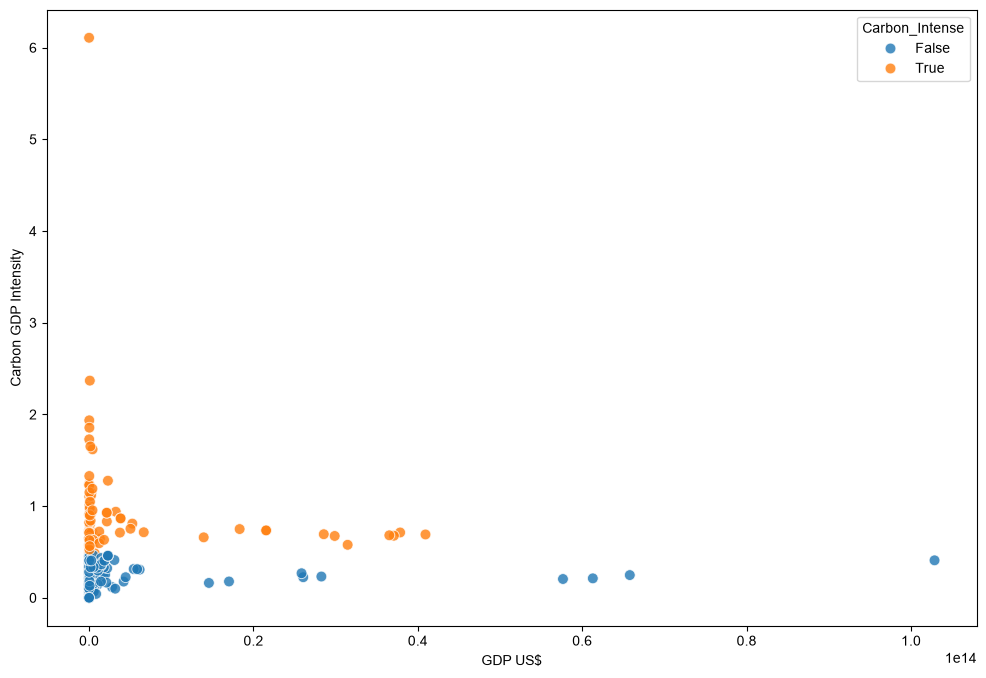

<Figure size 800x600 with 0 Axes>

In [22]:
# Making sure 'GDP US$' is numeric before plotting (might be redundant after already doing this above)
df101c['GDP US$'] = pd.to_numeric(df101c['GDP US$'], errors='coerce')

# Python's equivalent to ggplot() and geom_point() shown in tutorials
sns.scatterplot(
    data = df101c,
    x = 'GDP US$',
    y = 'Carbon GDP Intensity',
    hue = 'Carbon_Intense',
    s = 60,
    alpha = 0.8
)

# Setting theme
sns.set_style("ticks")
sns.set_context("notebook", font_scale = 1.3)
plt.figure(figsize = (8, 6))
sns.despine()

# Python's equivalent to ggsave()
plt.tight_layout()
plt.savefig("scatter_carbon.png", dpi = 300)
plt.show()

### I realise now that this is not very useful with just 2 variables
I am leaving this graph in to show my process behind choosing what variables to use but it will not count as one of my 4 required graphs for this notebook.

In [37]:
# I can still use what I have made so far to add an additional variable
df101s = pd.merge(left = df101,
                 right = ds_gdp_pcg,
                 how = 'left',
                 left_on = ['Country Code'],
                 right_on = ['Country Code'],
                )

Now just to repeat the steps before:

In [24]:
# Having another look at the columns so I have the right ones
print(df101s.columns.tolist())

['Country Code', 'Carbon GDP Intensity', 'GDP US$', 'GDP Per Capita Growth %']


In [25]:
# Double checking that everything is a number (and making a column variable to make less messy)
cols = ['GDP US$', 'Carbon GDP Intensity', 'GDP Per Capita Growth %']
df101s[cols] = df101s[cols].apply(pd.to_numeric, errors='coerce')

# Will now begin plotting
df101cs = (
    df101s
    .assign(growth=lambda x: x['GDP Per Capita Growth %'] > 0)
[['Country Code', 'growth', 'Carbon GDP Intensity', 'GDP US$']]
    .dropna()
)
print(df101cs)

    Country Code  growth  Carbon GDP Intensity       GDP US$
0            AFG   False              0.737216  1.449724e+10
1            ALB    True              0.314480  1.901725e+10
2            DZA    True              0.915412  2.255816e+11
3            ASM    True              0.000151  8.710000e+08
5            AGO    True              0.267622  1.282340e+11
..           ...     ...                   ...           ...
261          SSF    True              0.458645  2.290210e+12
262          SSA    True              0.458649  2.288210e+12
263          TSS    True              0.458645  2.290210e+12
264          UMC    True              0.674054  2.988158e+13
265          WLD    True              0.408213  1.028625e+14

[244 rows x 4 columns]


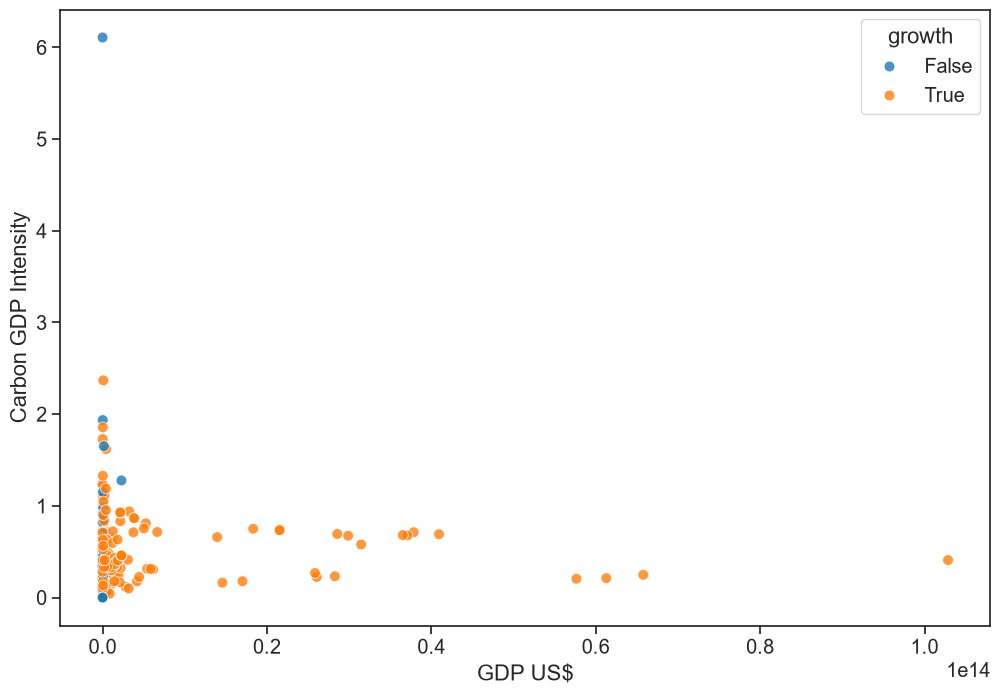

<Figure size 800x600 with 0 Axes>

In [26]:
# Python's equivalent to ggplot() and geom_point() shown in tutorials
sns.scatterplot(
    data = df101cs,
    x = 'GDP US$',
    y = 'Carbon GDP Intensity',
    hue = 'growth',
    s = 60,
    alpha = 0.8
)

# Setting theme
sns.set_style("ticks")
sns.set_context("notebook", font_scale = 1.3)
plt.figure(figsize = (8, 6))
sns.despine()

# Python's equivalent to ggsave()
plt.tight_layout()
plt.savefig("scatter_carbon_growth.png", dpi = 300)
plt.show()

An improvement but still not entirely useful or clear there is a correlation.
Might be better with GDP Per Capita on the x axis. 

### Graph 2

In [36]:
# Merging tables for graph (3)
df104s = pd.merge(left = df104,
                 right = ds_energy,
                 how = 'left',
                 left_on = ['Country Code'],
                 right_on = ['Country Code'],
                )

In [29]:
print(df104s.columns.tolist())

['Country Code', 'GDP Per Capita Growth %', 'GDP Per Capita US$', 'Net Energy Imports %']


In [38]:
cols2 = ['GDP Per Capita Growth %', 'GDP Per Capita US$', 'Net Energy Imports %']
df104s[cols2] = df104s[cols2].apply(pd.to_numeric, errors='coerce')

df104cs = (
    df104s
    .assign(net_energy_imports=lambda x: x['Net Energy Imports %'] > 0)
[['Country Code', 'net_energy_imports', 'GDP Per Capita Growth %', 'GDP Per Capita US$']]
    .dropna()
)
print(df104cs.columns.tolist())

['Country Code', 'net_energy_imports', 'GDP Per Capita Growth %', 'GDP Per Capita US$']


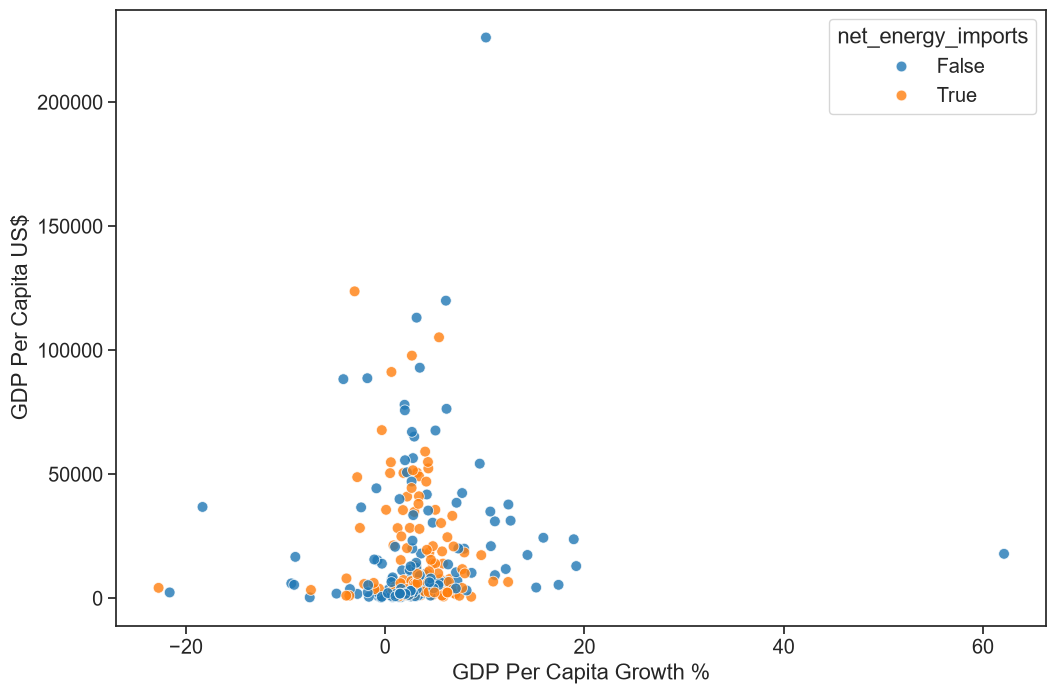

<Figure size 800x600 with 0 Axes>

In [35]:
sns.scatterplot(
    data = df104cs,
    x = 'GDP Per Capita Growth %',
    y = 'GDP Per Capita US$',
    hue = 'net_energy_imports',
    s = 60,
    alpha = 0.8
)

# Setting theme
sns.set_style("ticks")
sns.set_context("notebook", font_scale = 1.3)
plt.figure(figsize = (8, 6))
sns.despine()

# Python's equivalent to ggsave()
plt.tight_layout()
plt.savefig("scatter_gdppc_energy.png", dpi = 300)
plt.show()

### Graph 3

In [43]:
# Merging tables for graph (4)
df107s = pd.merge(left = df107,
                 right = ds_inflation,
                 how = 'left',
                 left_on = ['Country Code'],
                 right_on = ['Country Code'],
                )
print(df107s.columns.tolist())

['Country Code', 'Carbon GDP Intensity', 'GDP Per Capita US$', 'Consumer Price Inflation %']


In [64]:
cols3 = ['Carbon GDP Intensity', 'GDP Per Capita US$', 'Consumer Price Inflation %']
df107s[cols3] = df107s[cols3].apply(pd.to_numeric, errors='coerce')

df107cs = (
    df107s
    .assign(high_consumer_price_inflation=lambda x: x['Consumer Price Inflation %'] > 3)
[['Country Code', 'Carbon GDP Intensity', 'GDP Per Capita US$', 'high_consumer_price_inflation']]
    .dropna()
)
print(df107cs.columns.tolist())

['Country Code', 'Carbon GDP Intensity', 'GDP Per Capita US$', 'high_consumer_price_inflation']


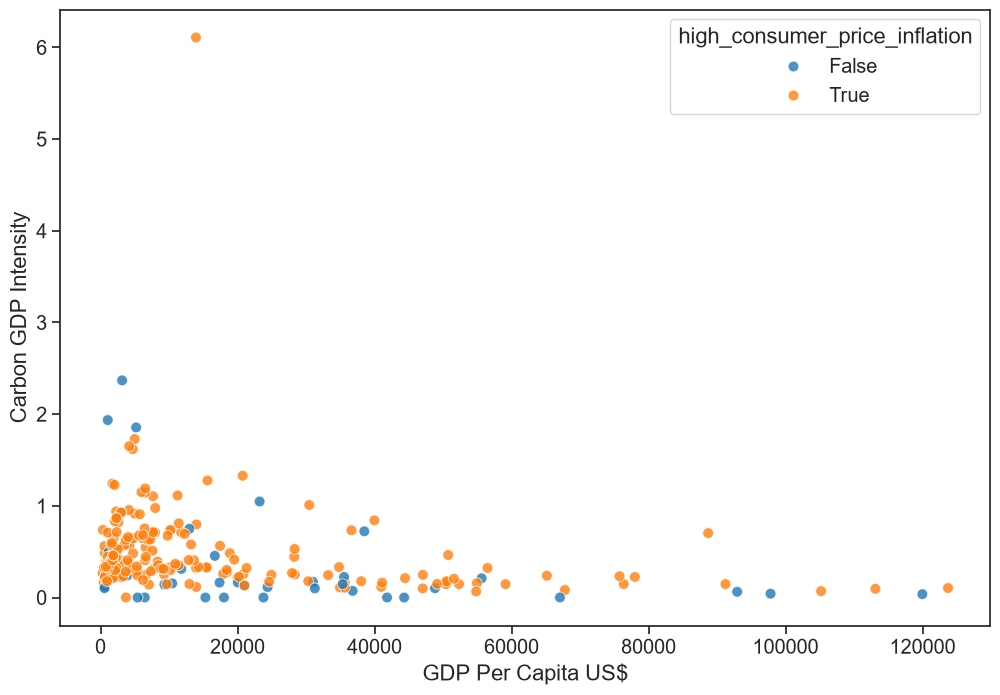

<Figure size 800x600 with 0 Axes>

In [65]:
sns.scatterplot(
    data = df107cs,
    x = 'GDP Per Capita US$',
    y = 'Carbon GDP Intensity',
    hue = 'high_consumer_price_inflation',
    s = 60,
    alpha = 0.8
)

# Setting theme
sns.set_style("ticks")
sns.set_context("notebook", font_scale = 1.3)
plt.figure(figsize = (8, 6))
sns.despine()

# Python's equivalent to ggsave()
plt.tight_layout()
plt.savefig("scatter_carbongdp_inflation.png", dpi = 300)
plt.show()

I would be interested to see how this graph would change if it was plotted with data from years up to and following 2022. 

### Graph 4

In [57]:
# Merging tables for graph (5)
df108s = pd.merge(left = df108,
                 right = ds_gdp_pcg,
                 how = 'left',
                 left_on = ['Country Code'],
                 right_on = ['Country Code'],
                )
print(df108s.columns.tolist())

['Country Code', 'GDP Per Capita US$', 'Consumer Price Inflation %', 'GDP Per Capita Growth %']


In [60]:
cols4 = ['GDP Per Capita US$', 'Consumer Price Inflation %', 'GDP Per Capita Growth %']
df108s[cols4] = df108s[cols4].apply(pd.to_numeric, errors='coerce')

df108cs = (
    df108s
    .assign(net_growth=lambda x: x['GDP Per Capita Growth %'] > x['Consumer Price Inflation %'])
[['Country Code', 'GDP Per Capita Growth %', 'Consumer Price Inflation %', 'net_growth']]
    .dropna()
)
print(df108cs.columns.tolist())

['Country Code', 'GDP Per Capita Growth %', 'Consumer Price Inflation %', 'net_growth']


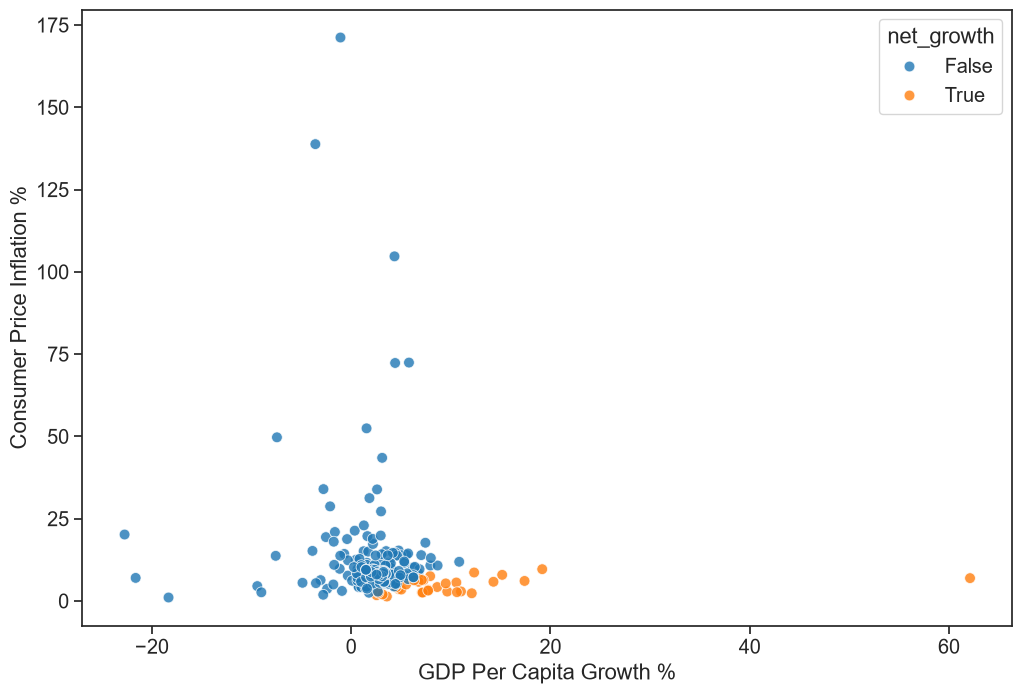

<Figure size 800x600 with 0 Axes>

In [61]:
sns.scatterplot(
    data = df108cs,
    x = 'GDP Per Capita Growth %',
    y = 'Consumer Price Inflation %',
    hue = 'net_growth',
    s = 60,
    alpha = 0.8
)

# Setting theme
sns.set_style("ticks")
sns.set_context("notebook", font_scale = 1.3)
plt.figure(figsize = (8, 6))
sns.despine()

# Python's equivalent to ggsave()
plt.tight_layout()
plt.savefig("scatter_GDP_Inflation_Growth.png", dpi = 300)
plt.show()

The graph originally had gdp per capita as the x axis but the results were so close they weren't useful. With this you can better see that most countries eneded up decreasing their gdp per capita when accounting for consumer price inflation in 2022. 

### Linear Discriminant Analysis (LDA)
For this I am going to use df107cs from graph 3

In [97]:
# Defining predictors (x) and target variable (y)
X_lda1 = df107cs[['GDP Per Capita US$', 'Carbon GDP Intensity']]
y_lda1 = df107cs['high_consumer_price_inflation']

#Split into training and testing sets
X_train_lda1, X_test_lda1, y_train_lda1, y_test_lda1 = train_test_split(
    X_lda1, y_lda1, test_size=0.2, random_state=42
)
# The random_state can apparently be any number but for some reason everyone writes 42. 
# Initialising and fitting the LDA model
lda1 = LinearDiscriminantAnalysis()
lda1.fit(X_train_lda1, y_train_lda1)

# Making predictions and evaluating the accuracy 
y_pred_lda1 = lda1.predict(X_test_lda1)
print("Accuracy:", accuracy_score(y_test_lda1, y_pred_lda1))
print(classification_report(y_test_lda1, y_pred_lda1, zero_division=0))

Accuracy: 0.8571428571428571
              precision    recall  f1-score   support

       False       0.00      0.00      0.00         7
        True       0.86      1.00      0.92        42

    accuracy                           0.86        49
   macro avg       0.43      0.50      0.46        49
weighted avg       0.73      0.86      0.79        49



Trying again with df104cs as df107cs may not be the appropriate table to use due to imbalancing in the variables

In [68]:
print(df104cs.columns.tolist())

['Country Code', 'net_energy_imports', 'GDP Per Capita Growth %', 'GDP Per Capita US$']


In [98]:
# Defining predictors (x) and target variable (y)
X_lda2 = df104cs[['GDP Per Capita Growth %', 'GDP Per Capita US$']]
y_lda2 = df104cs['net_energy_imports']

#Split into training and testing sets
X_train_lda2, X_test_lda2, y_train_lda2, y_test_lda2 = train_test_split(
    X_lda2, y_lda2, test_size=0.2, random_state=42
)

# Initialising and fitting the LDA model
lda2 = LinearDiscriminantAnalysis()
lda2.fit(X_train_lda2, y_train_lda2)

# Making predictions and evaluating the accuracy 
y_pred_lda2 = lda2.predict(X_test_lda2)
print("Accuracy:", accuracy_score(y_test_lda2, y_pred_lda2))
print(classification_report(y_test_lda2, y_pred_lda2))

Accuracy: 0.5
              precision    recall  f1-score   support

       False       0.54      0.83      0.66        30
        True       0.17      0.05      0.07        22

    accuracy                           0.50        52
   macro avg       0.36      0.44      0.36        52
weighted avg       0.38      0.50      0.41        52



### Support Vector Machine (SVM)
Using the same x and y variables from the LDR.

In [99]:
# Defining predictors (x) and target variable (y)
X_svm = df107cs[['GDP Per Capita US$', 'Carbon GDP Intensity']]
y_svm = df107cs['high_consumer_price_inflation']

#Split into training and testing sets
X_train_svm, X_test_svm, y_train_svm, y_test_svm = train_test_split(
    X_svm, y_svm, test_size=0.2, random_state=42
)
# I am not sure if changing the random state is a good thing so it shall stay at 42 because then everybody is wrong.

# Scaling needed to stop gdp from dominating the model
svm_model = make_pipeline(
    StandardScaler(),
    SVC(kernel='rbf', class_weight='balanced', random_state=42)
)

# Training and evaluating
svm_model.fit(X_train_svm, y_train_svm)
y_pred_svm = svm_model.predict(X_test_svm)

print("Accuracy:", accuracy_score(y_test_svm, y_pred_svm))
print(classification_report(y_test_svm, y_pred_svm, zero_division=0))

Accuracy: 0.6530612244897959
              precision    recall  f1-score   support

       False       0.22      0.57      0.32         7
        True       0.90      0.67      0.77        42

    accuracy                           0.65        49
   macro avg       0.56      0.62      0.54        49
weighted avg       0.81      0.65      0.70        49



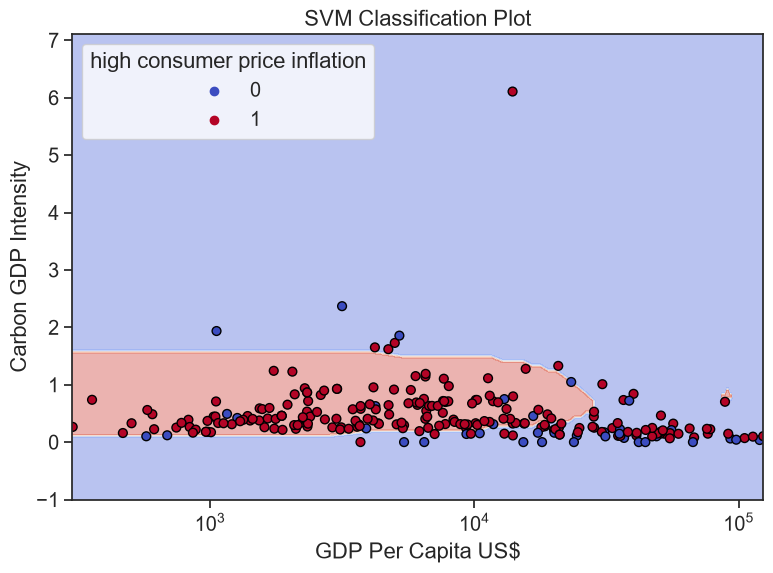

In [100]:
# PLotting
fig, ax = plt.subplots(figsize=(8, 6))

# Shaded decision regions
DecisionBoundaryDisplay.from_estimator(
    svm_model,
    X_svm,
    response_method="predict",
    cmap=plt.cm.coolwarm,
    alpha=0.4,
    ax=ax
)

# Overlaying data points
scatter = ax.scatter(
    X_svm['GDP Per Capita US$'],
    X_svm['Carbon GDP Intensity'],
    c=y,
    cmap=plt.cm.coolwarm,
    edgecolors='k',
    s=40
)

# Labels
ax.set_xlabel('GDP Per Capita US$')
ax.set_ylabel('Carbon GDP Intensity')
ax.set_title('SVM Classification Plot')
ax.legend(*scatter.legend_elements(), title="high consumer price inflation")
ax.set_xscale('symlog')

plt.tight_layout()
plt.show()

The example in the tutorial "classification_exercise_notebook.ipymb" used a linear predictor instead of mine. I think the rbf kernel (curved) is more appropriate for mine instead of linear due to the messy and hard-to-predict nature of the data.

### Probit Model
For this one I am going to use graph 2, which looks at the GDP per Capita and GDP per Capita Growth with Net Energy Imports as the predictor. (df104cs)

In [86]:
print(df104cs.columns.tolist())

['Country Code', 'net_energy_imports', 'GDP Per Capita Growth %', 'GDP Per Capita US$']


In [102]:
# Defining predictor variables (x) and adding an intercept column
X_pm = df104cs[['GDP Per Capita Growth %', 'GDP Per Capita US$']]
X_pm = sm.add_constant(X_pm)

# Making sure that the binary target variable (y) is numeric
y_pm = df104cs['net_energy_imports'].astype(int)

# Fitting the probit model 
probit_model = sm.Probit(y_pm, X_pm)
probit_results = probit_model.fit()

print(probit_results.summary())

Optimization terminated successfully.
         Current function value: 0.688282
         Iterations 4
                          Probit Regression Results                           
Dep. Variable:     net_energy_imports   No. Observations:                  256
Model:                         Probit   Df Residuals:                      253
Method:                           MLE   Df Model:                            2
Date:                Thu, 26 Nov 2026   Pseudo R-squ.:               0.0006742
Time:                        19:42:03   Log-Likelihood:                -176.20
converged:                       True   LL-Null:                       -176.32
Covariance Type:            nonrobust   LLR p-value:                    0.8879
                              coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------------------
const                      -0.0961      0.104     -0.921      0.357      -0.301   

### Classification Results

In [113]:
# LDA (using the 1st attempt)
conf_matrix_lda1 = pd.crosstab(
    index=y_test_lda1,
    columns=y_pred_lda1,
    rownames=['True'],
    colnames=['Predicted']
)
accuracy_lda1 = np.diag(conf_matrix_lda1).sum() / conf_matrix_lda1.to_numpy().sum()

print(conf_matrix_lda1)
print(f"\nAccuracy: {round(accuracy_lda1 * 100, 2)}%")

Predicted  True
True           
False         7
True         42

Accuracy: 14.29%


In [112]:
# LDA (using the 2nd attempt)
conf_matrix_lda2 = pd.crosstab(
    index=y_test_lda2,
    columns=y_pred_lda2,
    rownames=['True'],
    colnames=['Predicted']
)
accuracy_lda2 = np.diag(conf_matrix_lda2).sum() / conf_matrix_lda2.to_numpy().sum()

print(conf_matrix_lda2)
print(f"\nAccuracy: {round(accuracy_lda2 * 100, 2)}%")

Predicted  False  True 
True                   
False         25      5
True          21      1

Accuracy: 50.0%


In [114]:
# SVM
conf_matrix_svm = pd.crosstab(
    index=y_test_svm,
    columns=y_pred_svm,
    rownames=['True'],
    colnames=['Predicted']
)
accuracy_svm = np.diag(conf_matrix_svm).sum() / conf_matrix_svm.to_numpy().sum()

print(conf_matrix_svm)
print(f"\nAccuracy: {round(accuracy_svm * 100, 2)}%")

Predicted  False  True 
True                   
False          4      3
True          14     28

Accuracy: 65.31%


In [116]:
# Probit
# I have to do probit slightly differently to the previous ones because the model didn't give a y_pred_pm variable.
y_pred_pm = (probit_results.predict(X_pm) >= 0.5).astype(int)

conf_matrix_pm = pd.crosstab(
    index=y_pm,
    columns=y_pred_pm,
    rownames=['True'],
    colnames=['Predicted']
).reindex(index=[0, 1], columns=[0, 1], fill_value=0)

accuracy_pm = accuracy_score(y_pm, y_pred_pm)

print(conf_matrix_pm)
print(f"\nAccuracy: {round(accuracy_pm * 100, 2)}%")

Predicted    0  1
True             
0          138  2
1          115  1

Accuracy: 54.3%
